# Palier 2 · Le perceptron multicouche (MLP)

## 1. Imports, graine et données

In [1]:
# À mettre AVANT d'importer TensorFlow : désactive les optimisations oneDNN,
# qui changent l'ordre des calculs et donnent des résultats un peu différents à chaque lancement
import os
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"

import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

SEED = 42
keras.utils.set_random_seed(SEED)

print("Python    :", sys.version.split()[0])
print("NumPy     :", np.__version__)
print("TensorFlow:", tf.__version__)
print("Keras     :", keras.__version__)

Python    : 3.12.7
NumPy     : 2.5.5
TensorFlow: 2.21.0
Keras     : 3.15.1


In [2]:
# Les mêmes jeux que dans le notebook 1 (même découpage, même graine)
sys.path.append("..")
from src.data import load_data

x_train, y_train, x_val, y_val, x_test, y_test = load_data(seed=SEED)

# Un MLP prend un vecteur en entrée : 28 x 28 -> 784
X_train = x_train.reshape(len(x_train), 784)
X_val = x_val.reshape(len(x_val), 784)
X_test = x_test.reshape(len(x_test), 784)  # gardé pour la section 9 seulement

print("X_train :", X_train.shape, "/ X_val :", X_val.shape, "/ X_test :", X_test.shape)
print("Pixels entre", X_train.min(), "et", X_train.max())

X_train : (54000, 784) / X_val : (6000, 784) / X_test : (10000, 784)
Pixels entre 0.0 et 1.0


J'utilise les mêmes jeux que dans le notebook 1 : 54 000 images pour l'entraînement et 6 000 pour la validation, avec les pixels entre 0 et 1. J'aplatis chaque image en un vecteur de 784 pixels, parce qu'une couche `Dense` ne sait pas lire une image 2D. Je prépare aussi `X_test`, mais il ne servira qu'une seule fois, à la section 9.

*Reproductibilité :* en plus de la graine, je désactive oneDNN (`TF_ENABLE_ONEDNN_OPTS=0`, avant d'importer TensorFlow), et `run()` active `enable_op_determinism()`. Sans ça, j'obtenais 2,02 %, puis 2,10 %, puis 2,13 % d'erreur en relançant exactement le même code. Maintenant, deux relances donnent les mêmes chiffres au centième près (seule la durée varie).

## 2. Fonctions utiles : plot_history et run

J'ai mis les fonctions dans `src/utils.py` pour pouvoir les réutiliser dans le notebook du CNN :

- `build_mlp(hidden, dropout, batchnorm)` construit un MLP : entrée de 784 pixels → couches cachées ReLU → 10 sorties softmax ;
- `plot_history(history, titre)` trace la loss et l'erreur (1 − accuracy), pour l'entraînement et pour la validation, côte à côte ;
- `run(...)` fait un essai complet. Elle fixe la graine, **construit un modèle neuf**, compile, chronomètre l'entraînement, trace les courbes et ajoute une ligne au tableau `resultats`.

`run` reçoit une **fonction** qui crée le modèle (`lambda: build_mlp(...)`), et pas un modèle déjà construit. Comme ça, la graine est fixée *avant* l'initialisation des poids : chaque essai part des mêmes poids, et je ne continue jamais par erreur l'entraînement d'un ancien modèle.

In [3]:
from src.utils import build_mlp, plot_history, run

donnees = (X_train, y_train, X_val, y_val)   # jamais le test pendant les essais
resultats = []                               # une ligne par essai, affichée en tableau à la section 8

## 3. MLP de référence

In [4]:
# On construit une fois le modèle juste pour lire son résumé
keras.utils.set_random_seed(SEED)
build_mlp(hidden=(256,)).summary()

Model: "mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 203,530 (795.04 KB)

 Trainable params: 203,530 (795.04 KB)

 Non-trainable params: 0 (0.00 B)

**Calcul du nombre de paramètres à la main** (un poids par connexion, plus un biais par neurone) :

| couche | calcul | paramètres |
|---|---|---|
| Dense 784 → 256 | 784 × 256 + 256 | 200 960 |
| Dense 256 → 10 | 256 × 10 + 10 | 2 570 |
| **total** | | **203 530** |

C'est exactement ce qu'affiche `summary()` (203 530). Presque tout est dans la première couche (99 %), parce que chaque pixel est relié à chacun des 256 neurones.

Epoch 1/20


422/422 - 2s - 6ms/step - accuracy: 0.9117 - loss: 0.3142 - val_accuracy: 0.9505 - val_loss: 0.1809


Epoch 2/20


422/422 - 1s - 3ms/step - accuracy: 0.9611 - loss: 0.1357 - val_accuracy: 0.9650 - val_loss: 0.1315


Epoch 3/20


422/422 - 1s - 3ms/step - accuracy: 0.9733 - loss: 0.0936 - val_accuracy: 0.9697 - val_loss: 0.1101


... (30 outputs left out)

Epoch 19/20


422/422 - 1s - 3ms/step - accuracy: 0.9993 - loss: 0.0038 - val_accuracy: 0.9808 - val_loss: 0.0991


Epoch 20/20


422/422 - 1s - 4ms/step - accuracy: 0.9997 - loss: 0.0024 - val_accuracy: 0.9797 - val_loss: 0.1016


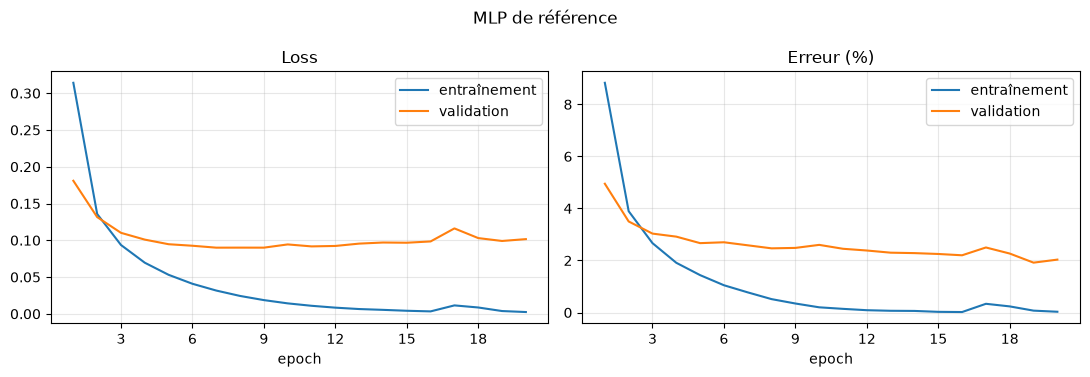

In [5]:
# Référence : 784 -> 256 (ReLU) -> 10 (softmax), Adam lr = 0,001, batch 128, 20 epochs
model_ref, hist_ref = run(
    "MLP de référence",
    creer_modele=lambda: build_mlp(hidden=(256,)),
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    donnees=donnees,
    resultats=resultats,
    batch_size=128,
    epochs=20,
    changement="référence : 256 neurones, Adam 1e-3, batch 128",
    save="../images/p2_ref_courbes.png",
)

In [6]:
pd.DataFrame(resultats)

,nom,changement,parametres,epochs,erreur_val_%,meilleure_erreur_val_%,epoch_meilleure,duree_s
0,MLP de référence,"référence : 256 neurones, Adam 1e-3, batch 128",203530,20,2.03,1.92,19,31.4


**Pourquoi 422 itérations par epoch ?** Une itération, c'est un paquet (batch) de 128 images : le modèle calcule l'erreur sur ce paquet, puis corrige ses poids une fois. Pour voir les 54 000 images une fois (= une epoch), il faut 54 000 / 128 = 421,875 paquets. On fait donc 421 paquets complets, plus un dernier paquet de 54 000 − 421 × 128 = **112 images**, soit **422 itérations**. C'est bien le `422/422` affiché par Keras à chaque epoch.

**Ce que je lis sur les courbes** (`images/p2_ref_courbes.png`) :

- L'erreur de **validation** baisse vite : 4,95 % après la 1re epoch, environ 2,6 % à l'epoch 7. Ensuite, elle descend lentement : **1,92 % au mieux (epoch 19)** et **2,03 % à la fin (epoch 20)**.
- Pendant ce temps, l'erreur d'**entraînement** tombe presque à 0 % (accuracy de 99,97 %) : le modèle a quasiment appris les 54 000 images par cœur.
- La **loss de validation** est au plus bas entre les epochs 7 et 9 (0,090), puis elle remonte (0,102 à la fin), alors que la loss d'entraînement continue de baisser. **C'est un début de surapprentissage** : le modèle devient trop sûr de lui sur les images de validation qu'il classe mal, même si le nombre d'erreurs ne remonte pas encore. L'écart entre train et validation s'agrandit. Je traiterai ça à la section 6 (dropout, early stopping).
- Il y a un pic à l'epoch 17 : la loss d'entraînement remonte d'un coup (de 0,003 à 0,011), et l'erreur de validation aussi. C'est un « à-coup » d'Adam quand la loss est déjà presque nulle, et il se corrige dès les epochs suivantes.
- L'entraînement prend environ 30 s sur le CPU (environ 1,5 s par epoch).

**Comparaison avec la baseline :** le MLP de référence fait **2,03 %** d'erreur sur la validation à la fin (1,92 % au mieux), contre **3,42 %** pour la forêt aléatoire du notebook 1. La baseline est battue ✅ (environ 40 % d'erreurs en moins).

## 4. Comparaison de configurations (une variable à la fois)

Je garde la référence du jour 4 (784 → 256 → 10, Adam 0,001, batch 128, 20 epochs) et je change **une seule chose à la fois**. Comme ça, si l'erreur change, je sais d'où ça vient. Tous les essais ont la même graine, les mêmes données et 20 epochs. Le jeu de test n'est jamais utilisé.

Epoch 1/20


422/422 - 5s - 11ms/step - accuracy: 0.9207 - loss: 0.2783 - val_accuracy: 0.9547 - val_loss: 0.1605


Epoch 2/20


422/422 - 5s - 11ms/step - accuracy: 0.9674 - loss: 0.1139 - val_accuracy: 0.9675 - val_loss: 0.1149


Epoch 3/20


422/422 - 3s - 8ms/step - accuracy: 0.9792 - loss: 0.0736 - val_accuracy: 0.9737 - val_loss: 0.0966


... (30 outputs left out)

Epoch 19/20


422/422 - 3s - 8ms/step - accuracy: 0.9998 - loss: 0.0012 - val_accuracy: 0.9807 - val_loss: 0.1027


Epoch 20/20


422/422 - 3s - 8ms/step - accuracy: 0.9993 - loss: 0.0029 - val_accuracy: 0.9820 - val_loss: 0.1009


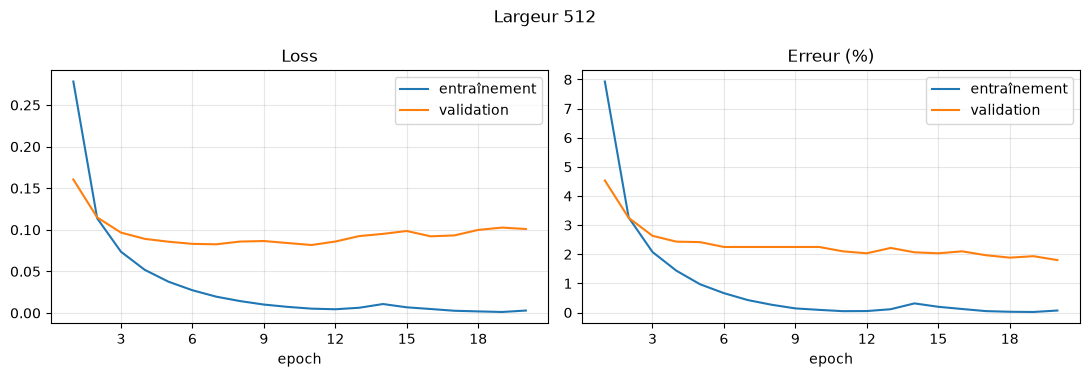

In [7]:
# Essai 1 : LARGEUR -> 512 neurones dans la couche cachée (tout le reste = référence)
model_512, hist_512 = run(
    "Largeur 512",
    creer_modele=lambda: build_mlp(hidden=(512,)),
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    donnees=donnees,
    resultats=resultats,
    batch_size=128,
    epochs=20,
    changement="largeur : 512 neurones au lieu de 256",
    save="../images/p2_largeur_512.png",
)

Epoch 1/20


422/422 - 3s - 7ms/step - accuracy: 0.9186 - loss: 0.2831 - val_accuracy: 0.9568 - val_loss: 0.1568


Epoch 2/20


422/422 - 2s - 4ms/step - accuracy: 0.9674 - loss: 0.1090 - val_accuracy: 0.9638 - val_loss: 0.1257


Epoch 3/20


422/422 - 2s - 4ms/step - accuracy: 0.9794 - loss: 0.0704 - val_accuracy: 0.9695 - val_loss: 0.1025


... (30 outputs left out)

Epoch 19/20


422/422 - 2s - 4ms/step - accuracy: 0.9973 - loss: 0.0082 - val_accuracy: 0.9757 - val_loss: 0.1434


Epoch 20/20


422/422 - 2s - 4ms/step - accuracy: 0.9974 - loss: 0.0079 - val_accuracy: 0.9775 - val_loss: 0.1327


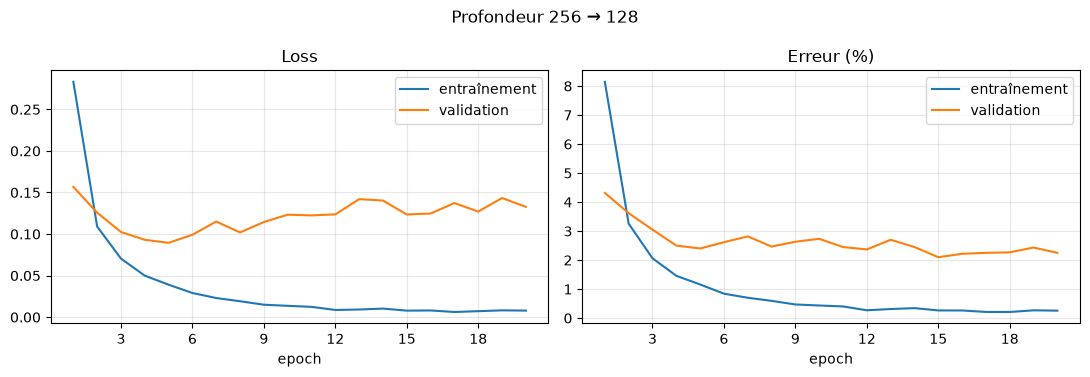

In [8]:
# Essai 2 : PROFONDEUR -> deux couches cachées 256 puis 128
model_deux_couches, hist_deux_couches = run(
    "Profondeur 256 → 128",
    creer_modele=lambda: build_mlp(hidden=(256, 128)),
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    donnees=donnees,
    resultats=resultats,
    batch_size=128,
    epochs=20,
    changement="profondeur : 2 couches cachées (256 → 128)",
    save="../images/p2_profondeur_256_128.png",
)

Epoch 1/20


1688/1688 - 7s - 4ms/step - accuracy: 0.9318 - loss: 0.2317 - val_accuracy: 0.9567 - val_loss: 0.1437


Epoch 2/20


1688/1688 - 6s - 3ms/step - accuracy: 0.9713 - loss: 0.0951 - val_accuracy: 0.9682 - val_loss: 0.1088


Epoch 3/20


1688/1688 - 6s - 3ms/step - accuracy: 0.9823 - loss: 0.0598 - val_accuracy: 0.9745 - val_loss: 0.0943


... (30 outputs left out)

Epoch 19/20


1688/1688 - 5s - 3ms/step - accuracy: 0.9977 - loss: 0.0062 - val_accuracy: 0.9775 - val_loss: 0.1372


Epoch 20/20


1688/1688 - 5s - 3ms/step - accuracy: 0.9985 - loss: 0.0042 - val_accuracy: 0.9763 - val_loss: 0.1565


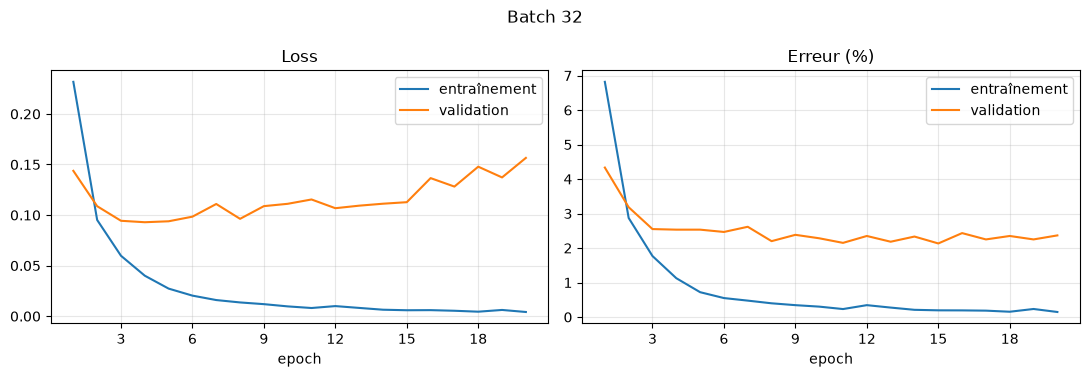

In [9]:
# Essai 3 : BATCH SIZE -> 32 (54 000 / 32 = 1 687,5 -> 1 688 itérations par epoch)
model_b32, hist_b32 = run(
    "Batch 32",
    creer_modele=lambda: build_mlp(hidden=(256,)),
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    donnees=donnees,
    resultats=resultats,
    batch_size=32,
    epochs=20,
    changement="batch size : 32 au lieu de 128",
    save="../images/p2_batch_32.png",
)

Epoch 1/20


106/106 - 2s - 15ms/step - accuracy: 0.8634 - loss: 0.5100 - val_accuracy: 0.9283 - val_loss: 0.2630


Epoch 2/20


106/106 - 1s - 8ms/step - accuracy: 0.9392 - loss: 0.2158 - val_accuracy: 0.9460 - val_loss: 0.1962


Epoch 3/20


106/106 - 1s - 8ms/step - accuracy: 0.9551 - loss: 0.1600 - val_accuracy: 0.9547 - val_loss: 0.1601


... (30 outputs left out)

Epoch 19/20


106/106 - 1s - 7ms/step - accuracy: 0.9981 - loss: 0.0153 - val_accuracy: 0.9768 - val_loss: 0.0865


Epoch 20/20


106/106 - 1s - 8ms/step - accuracy: 0.9985 - loss: 0.0137 - val_accuracy: 0.9763 - val_loss: 0.0872


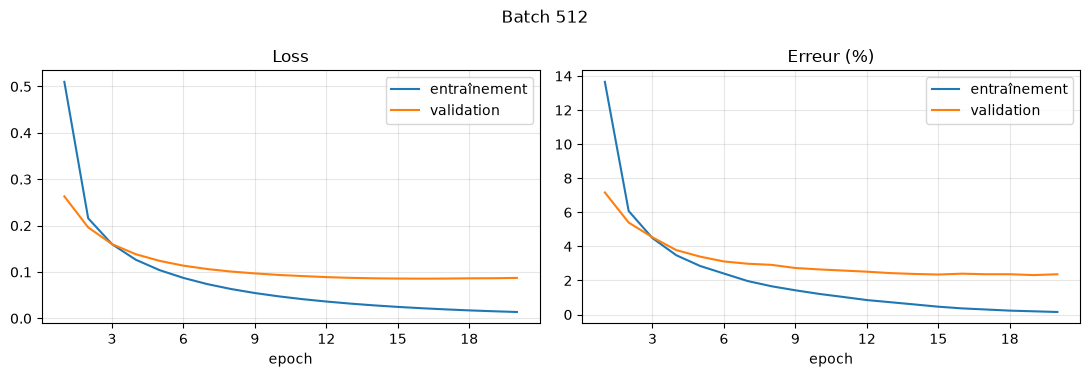

In [10]:
# Essai 4 : BATCH SIZE -> 512 (54 000 / 512 = 105,5 -> 106 itérations par epoch)
model_b512, hist_b512 = run(
    "Batch 512",
    creer_modele=lambda: build_mlp(hidden=(256,)),
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    donnees=donnees,
    resultats=resultats,
    batch_size=512,
    epochs=20,
    changement="batch size : 512 au lieu de 128",
    save="../images/p2_batch_512.png",
)

Epoch 1/20


422/422 - 2s - 4ms/step - accuracy: 0.7281 - loss: 1.1796 - val_accuracy: 0.8438 - val_loss: 0.6858


Epoch 2/20


422/422 - 1s - 3ms/step - accuracy: 0.8635 - loss: 0.5639 - val_accuracy: 0.8750 - val_loss: 0.4919


Epoch 3/20


422/422 - 1s - 3ms/step - accuracy: 0.8839 - loss: 0.4476 - val_accuracy: 0.8888 - val_loss: 0.4204


... (30 outputs left out)

Epoch 19/20


422/422 - 2s - 4ms/step - accuracy: 0.9363 - loss: 0.2285 - val_accuracy: 0.9325 - val_loss: 0.2430


Epoch 20/20


422/422 - 1s - 3ms/step - accuracy: 0.9374 - loss: 0.2237 - val_accuracy: 0.9348 - val_loss: 0.2389


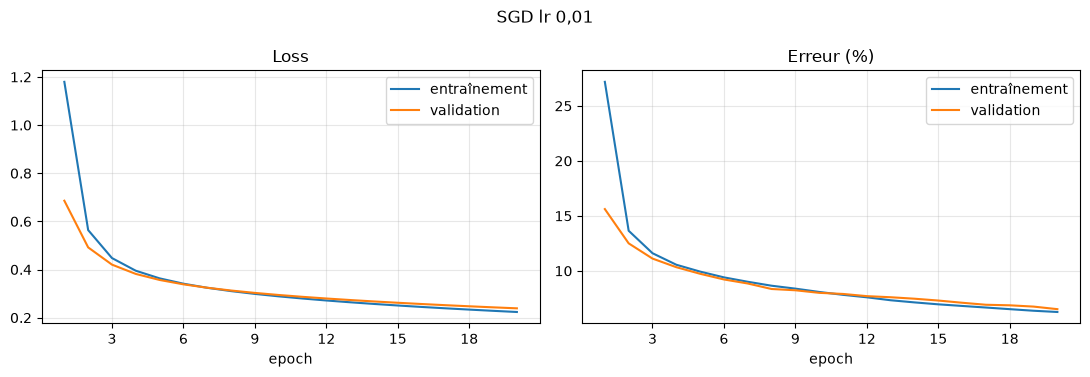

In [11]:
# Essai 5 : OPTIMISEUR -> SGD simple avec lr = 0,01 (une valeur classique pour SGD)
model_sgd, hist_sgd = run(
    "SGD lr 0,01",
    creer_modele=lambda: build_mlp(hidden=(256,)),
    optimizer=keras.optimizers.SGD(learning_rate=0.01),
    donnees=donnees,
    resultats=resultats,
    batch_size=128,
    epochs=20,
    changement="optimiseur : SGD (lr 0,01) au lieu d'Adam (lr 0,001)",
    save="../images/p2_sgd.png",
)

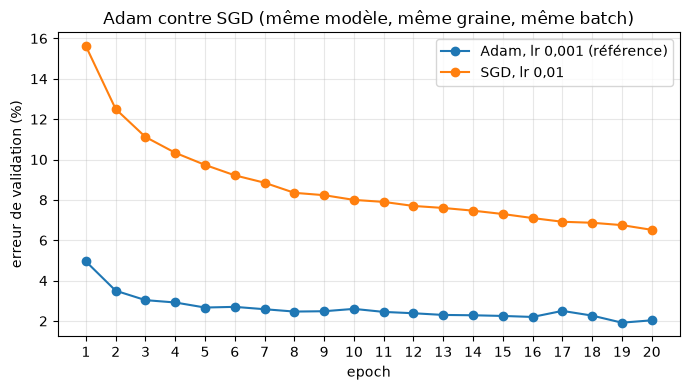

epoch  1 : Adam 4.95 %  |  SGD 15.62 %
epoch  5 : Adam 2.67 %  |  SGD 9.73 %
epoch 10 : Adam 2.60 %  |  SGD 8.00 %
epoch 20 : Adam 2.03 %  |  SGD 6.52 %


In [12]:
# Adam (référence) contre SGD : erreur de validation à chaque epoch, sur le même graphique
def erreur_val(hist):
    return 100 * (1 - np.array(hist.history["val_accuracy"]))

epochs = np.arange(1, 21)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(epochs, erreur_val(hist_ref), marker="o", label="Adam, lr 0,001 (référence)")
ax.plot(epochs, erreur_val(hist_sgd), marker="o", label="SGD, lr 0,01")
ax.set_xlabel("epoch")
ax.set_ylabel("erreur de validation (%)")
ax.set_xticks(epochs)
ax.set_title("Adam contre SGD (même modèle, même graine, même batch)")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig("../images/p2_adam_vs_sgd.png", dpi=100, bbox_inches="tight")
plt.show()

for e in [1, 5, 10, 20]:
    print(f"epoch {e:2d} : Adam {erreur_val(hist_ref)[e - 1]:.2f} %  |  SGD {erreur_val(hist_sgd)[e - 1]:.2f} %")

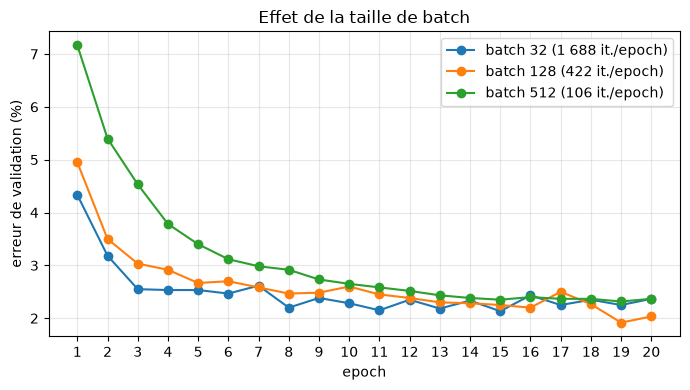

In [13]:
# Les trois tailles de batch sur le même graphique
fig, ax = plt.subplots(figsize=(7, 4))
for hist, nom in [(hist_b32, "batch 32 (1 688 it./epoch)"),
                  (hist_ref, "batch 128 (422 it./epoch)"),
                  (hist_b512, "batch 512 (106 it./epoch)")]:
    ax.plot(epochs, erreur_val(hist), marker="o", label=nom)
ax.set_xlabel("epoch")
ax.set_ylabel("erreur de validation (%)")
ax.set_xticks(epochs)
ax.set_title("Effet de la taille de batch")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig("../images/p2_batch_sizes.png", dpi=100, bbox_inches="tight")
plt.show()

In [14]:
# Tableau des essais, du meilleur au moins bon (erreur de validation à la dernière epoch)
tableau = pd.DataFrame(resultats).sort_values("erreur_val_%").reset_index(drop=True)
tableau

,nom,changement,parametres,epochs,erreur_val_%,meilleure_erreur_val_%,epoch_meilleure,duree_s
0,Largeur 512,largeur : 512 neurones au lieu de 256,407050,20,1.80,1.80,20,74.3
1,MLP de référence,"référence : 256 neurones, Adam 1e-3, batch 128",203530,20,2.03,1.92,19,31.4
2,Profondeur 256 → 128,profondeur : 2 couches cachées (256 → 128),235146,20,2.25,2.10,15,40.0
3,Batch 32,batch size : 32 au lieu de 128,203530,20,2.37,2.13,15,112.1
4,Batch 512,batch size : 512 au lieu de 128,203530,20,2.37,2.32,19,17.2
5,"SGD lr 0,01","optimiseur : SGD (lr 0,01) au lieu d'Adam (lr ...",203530,20,6.52,6.52,20,26.6


**Ce que je retiens du tableau** (erreur de validation à l'epoch 20 ; sur 6 000 images, 0,1 % = 6 images) :

- **Ce qui a aidé :** la **largeur 512** fait 1,80 % d'erreur contre 2,03 % pour la référence, soit 14 images de moins mal classées. Mais c'est avec 2 fois plus de paramètres (407 050) et 2 fois plus de temps (environ 75 s contre 30 à 35 s).
- **Ce qui n'a rien changé (ou un peu moins bien) :** la **2e couche cachée** (2,25 %), le **batch 32** (2,37 %) et le **batch 512** (2,37 %). Les écarts sont de 0,2 à 0,3 point, soit 13 à 20 images. Avec une seule graine, je ne peux pas affirmer que c'est vraiment moins bien : ça reste du même ordre que la référence.
- **Ce qui a coûté du temps :** le **batch 32** fait 1 688 itérations par epoch au lieu de 422, et il prend environ 110 à 130 s, 3 à 4 fois la référence, pour un résultat qui n'est pas meilleur. À l'inverse, le **batch 512** (106 itérations par epoch) est le plus rapide (environ 17 à 20 s), mais il démarre plus lentement (7,2 % d'erreur après l'epoch 1, contre 5,0 % pour la référence).
- **Ce qui a clairement fait pire :** **SGD** (lr 0,01) fait 6,52 % d'erreur après 20 epochs, plus de 3 fois l'erreur d'Adam, pour une durée du même ordre. Sa courbe descend encore : il n'a pas fini d'apprendre.

➡️ Pour la suite, je garde la référence (256 neurones, Adam, batch 128) comme base : c'est le meilleur compromis entre erreur et temps. Je retiens que la largeur 512 est la piste la plus prometteuse.

## 5. Learning rate trop bas / trop élevé

## 6. Surapprentissage et sa correction

## 7. Batch normalization : avec et sans

## 8. Tableau récapitulatif et choix du meilleur modèle (sur la validation)

## 9. Évaluation finale sur le test (une seule fois)

## 10. Réponses aux questions d'explication

**Q1. Avec 54 000 images d'entraînement et un batch de 128, combien d'itérations par epoch ? Que changent epochs, itérations et batch size à ce que j'observe ?**

54 000 / 128 = 421,875, donc **422 itérations par epoch** : 421 paquets de 128 images et un dernier paquet de 112. Keras affiche bien `422/422`.

- Une **itération** = une correction des poids, calculée sur un paquet d'images.
- Une **epoch** = un passage sur les 54 000 images.
- La **taille de batch** fixe le nombre d'itérations par epoch : 1 688 avec un batch de 32, 422 avec 128, et 106 avec 512.

Ce que je vois sur mes essais (`images/p2_batch_sizes.png`) :

- Avec un **petit batch (32)**, le modèle fait 4 fois plus de corrections par epoch. Il apprend donc plus vite *par epoch* : 4,3 % d'erreur après l'epoch 1, contre 5,0 % avec 128 et 7,2 % avec 512. Mais chaque epoch est plus longue (environ 6 s contre environ 1,5 s), et la courbe est plus « bruitée », parce que chaque correction est calculée sur peu d'images. Au total : environ 110 à 130 s, pour 2,37 % d'erreur.
- Avec un **gros batch (512)**, il y a seulement 106 corrections par epoch. Elles sont plus stables, mais il en faut plus d'epochs pour arriver au même niveau. C'est le plus rapide (environ 17 à 20 s), et il finit à 2,37 % d'erreur, comme le batch 32.
- Plus d'**epochs**, c'est plus de corrections. Sur la référence, l'erreur de validation baisse encore lentement jusqu'à l'epoch 20, mais la loss de validation remonte dès l'epoch 7 à 9 (début de surapprentissage). Ajouter des epochs n'aide donc plus beaucoup.

Au bout de 20 epochs, les trois tailles de batch arrivent au même niveau (entre 2,0 et 2,4 %). Ce qui change surtout, c'est **le temps** et **la vitesse de départ**.

**Q2. Learning rate trop bas et trop élevé : les conséquences sur les courbes.**

*À compléter (jour 6, section 5).*

**Q3. La Batch normalization a-t-elle aidé sur mon modèle ?**

*À compléter (jour 7, section 7).*

**Q4. Adam face à SGD : lequel converge le plus vite chez moi, et pourquoi, selon moi ?**

**Adam converge beaucoup plus vite.** Même modèle (784 → 256 → 10), même graine, même batch de 128, 20 epochs. Seul l'optimiseur change : Adam avec lr 0,001 (la valeur par défaut), contre SGD avec lr 0,01 (une valeur classique et raisonnable pour SGD). Voici l'erreur de validation (`images/p2_adam_vs_sgd.png`) :

| epoch | Adam | SGD |
|---|---|---|
| 1 | 4,95 % | 15,62 % |
| 5 | 2,67 % | 9,73 % |
| 10 | 2,60 % | 8,00 % |
| 20 | 2,03 % | 6,52 % |

Adam atteint en **une seule epoch** une erreur que SGD n'atteint toujours pas après 20 epochs. La durée est du même ordre (environ 25 à 35 s) : ce n'est pas plus lent par epoch, c'est juste que chaque pas d'Adam est plus « efficace ».

**Pourquoi, selon moi :** SGD fait des pas de **même taille** pour tous les poids, toujours dans la direction du gradient du paquet en cours. Si le pas est petit, il avance lentement. Adam, lui, adapte la taille du pas **pour chaque poids** : un poids dont le gradient est faible mais constant reçoit un pas plus grand. Il garde aussi une **moyenne des gradients précédents** (le « momentum »), ce qui lisse les directions et l'empêche de zigzaguer. Résultat : il descend la loss bien plus vite au début.

SGD n'est pas « mauvais » pour autant : sa courbe descend encore à l'epoch 20. Avec plus d'epochs, un lr plus grand ou du momentum, il finirait sûrement par se rapprocher d'Adam. Mais à budget égal (20 epochs), Adam gagne nettement.

## 11. Bilan du palier 2